# Morphology of the same galaxies in SDSS r-band imaging, measured exactly as in the Rubin notebook

**Input:** any CSV with `gid`, `ra`, `dec`. The default is the Rubin morphology CSV, so the same galaxies are measured.
**Output:** `{CATALOG}_sdss_r_morphology.csv`, with the same columns as the Rubin CSV, plus pickled `SourceMorphology`
objects in `{CATALOG}_sdss_r_morphology_pkl/{gid}.pkl`.

This notebook is generated from `rubin_morphology.ipynb`. The statmorph-lsst install, its fixes, the speed-up, the
Sérsic toggle and every measurement step are copied unchanged:
- sky and noise, segmentation, cutout growth and the weight map;
- the statmorph-lsst call and all of its settings;
- the output table and the parallel run.

The measurement settings (`CUTOUT_ARCSEC`, `CUTOUT_MAX_ARCSEC`, `ISOPHOTES_MU`, `STATMORPH_KW`) are copied unchanged too,
and so are the parameters set in pixels: detection areas, dilation, and statmorph's boxcars and sky box. In pixels they
are identical, so on the sky they cover (0.396/0.2)² ≈ 3.9× the area in SDSS. That difference is part of the resolution
effect being compared.

Only the data access is replaced, product for product:

| | Rubin notebook | This notebook |
|---|---|---|
| Image | DP2 `deep_coadd`, nJy | SDSS r-band corrected frame (`frame-r-…fits.bz2`), nanomaggies × 3631 = nJy |
| Background | `"pretty"` background restored | SDSS's own sky subtraction, as delivered (there is no alternative SDSS product) |
| Stitching | patches of one tract, on one pixel grid | consecutive fields of one run and camcol, on one pixel grid (drift scan); checked with each frame's WCS |
| Off the edge | past the tract: masked | past the camcol edge (2048 columns): masked |
| Variance | coadd variance plane | rebuilt from counts: dn = img/cimg + sky; σ² = dn/gain + darkVariance (SDSS frame data model) |
| Mask | `NO_DATA`, `SATURATED` | no data, and the `SATUR` regions of the fpM mask file (each region's bounding box) |
| Neighbours | found in the Rubin image | the Rubin run's neighbours (`RUBIN_NEIGHBOURS`), masked at the same sky positions, plus any found here |
| PSF | coadd PSF at the galaxy | psField KL PSF at the galaxy (`pydl.photoop.image.sdss_psf_recon`) |
| Which images | the tract containing the galaxy | the run/camcol/field of the nearest SDSS **primary** object within `MATCH_RADIUS_ARCSEC` |
| Band | `BAND`, else the nearest available band | r only |

What remains different between the two outputs is the data itself:
- depth, pixel scale (0.2″ vs 0.396″) and seeing;
- the observatories' processing: background subtraction and calibration;
- single-epoch SDSS imaging versus the Rubin coadd.

## 1. Settings

In [22]:
CATALOG = "goto"
INPUT_CSV = f"{CATALOG}_dp2_morphology.csv"      # any CSV with gid, ra, dec (default: the galaxies of the Rubin run)
RUBIN_NEIGHBOURS = f"{CATALOG}_dp2_neighbours"   # the Rubin run's neighbour masks: masked here too, at the same sky positions
                                                 #   (None: this notebook's own segmentation only)
BAND = "r"                                       # SDSS r band only; no other band is tried

OUT_CSV = f"{CATALOG}_sdss_r_morphology.csv"
OUT_PKL_DIR = f"{CATALOG}_sdss_r_morphology_pkl"
RESUME = True                              # keep galaxies already measured in OUT_CSV; measure the rest
FIT_SERSIC = False                         # statmorph-lsst's PSF-convolved single-Sersic fit (about half the run time)
N_WORKERS = "auto"                         # statmorph processes run in parallel: "auto" = one per CPU of this server;
                                           #   1 = one galaxy at a time (no parallel processes)

SDSS_CACHE = "sdss_cache"                        # downloaded frame, psField and fpM files (about 3 MB per field)
MATCH_RADIUS_ARCSEC = 2.0                        # SDSS primary object whose run/camcol/field is used
MASK_SATURATED = True                            # SDSS equivalent of the Rubin MASK_PLANES = ["NO_DATA", "SATURATED"]

# measurement settings: copied unchanged from rubin_morphology.ipynb
CUTOUT_ARCSEC = 60.0                       # starting cutout side; grown x1.5 until statmorph's stamp fits
CUTOUT_MAX_ARCSEC = 240.0
ISOPHOTES_MU = [24.0, 25.0]                # mag/arcsec^2 (observed, band used) for the isophotal asymmetry
STATMORPH_KW = dict(cutout_extent=2.5, min_cutout_size=48, n_sigma_outlier=10, petro_extent_flux=2.0,
                    niter_bh_mid=5)        # statmorph-lsst defaults

## 2. `statmorph-lsst`

The same commit as the Rubin notebook, plus `pydl` (SDSS PSF reconstruction) and `astroquery` (SDSS SQL).

In [20]:
import os, subprocess, sys

STATMORPH_LSST_COMMIT = "ee0600dba38cd4b754a92af0188391863b771de8"
STATMORPH_LSST_DIR = os.path.expanduser("~/software/statmorph-lsst")
if not os.path.isdir(os.path.join(STATMORPH_LSST_DIR, ".git")):
    os.makedirs(os.path.dirname(STATMORPH_LSST_DIR), exist_ok=True)
    subprocess.run(["git", "clone", "--quiet", "https://github.com/astro-nova/statmorph-lsst.git", STATMORPH_LSST_DIR], check=True)
subprocess.run(["git", "-C", STATMORPH_LSST_DIR, "fetch", "--quiet", "origin"], check=False)
subprocess.run(["git", "-C", STATMORPH_LSST_DIR, "checkout", "--quiet", STATMORPH_LSST_COMMIT], check=True)
if STATMORPH_LSST_DIR not in sys.path:
    sys.path.insert(0, STATMORPH_LSST_DIR)

import skimage, photutils
from packaging.version import Version
assert Version(skimage.__version__) >= Version("0.25.2"), \
    "statmorph-lsst needs scikit-image >= 0.25.2:  pip install --user 'scikit-image>=0.25.2'  then restart the kernel"
assert Version("2.0") <= Version(photutils.__version__) < Version("4.0"), \
    "statmorph-lsst needs 2.0 <= photutils < 4:  pip install --user 'photutils>=2,<4'  then restart the kernel"

**Three fixes, one speed-up and the Sérsic toggle**, applied to statmorph-lsst at runtime:

1. **pandas ≥ 3 crash** (no effect on the numbers). Its masked-pixel interpolation returns a read-only array, which
   statmorph-lsst then writes into. Every galaxy with a mask fails with "assignment destination is read-only".
2. **Sky terms of smoothness $S$ and substructure $St$.** statmorph-lsst divides the sky term by `np.sum(bkg)`, the *sum* of
   the sky-box pixel values. On a sky-subtracted image that sum is ≈ 0, so $S$ came out anywhere from −27 to +26 on smooth test
   galaxies, and good measurements were flagged 2 ("Invalid smoothness"). The original statmorph (v0.7.2) uses a per-pixel
   mean, which is what the formula needs. Both terms are restored to per-pixel means over the valid sky-box pixels. Nothing
   else changes.
3. **Asymmetry-centre tolerance** (speed-up). The centre that minimises the asymmetry is searched to 10⁻⁶ px, but the
   180° rotation inside the search uses the nearest pixel, so steps that fine change nothing. 0.01 px makes each galaxy about
   1.4× faster; in tests no statistic changed by more than 0.001.
4. **`FIT_SERSIC = False`** skips the Sérsic fit: the `sersic_*` values of the object are −99 and `flag_sersic` = 4
   (statmorph's convention for "not measured"), and the Sérsic columns are left out of the CSV.
5. **Galaxies with $R_p$ < 4 px crash.** $S$ and $St$ subtract a copy of the image smoothed with a box
   `int(0.25 × R_p)` pixels wide. Below $R_p$ = 4 px (0.8″ on Rubin's 0.2″ pixels, 1.6″ on SDSS's 0.396″) the box is
   0 px, astropy's `Box2DKernel` divides by zero, and the whole galaxy is lost ("ZeroDivisionError … kernels.py:310").
   An unresolved source has $R_p$ ≈ 1.3–1.4″ in SDSS seeing, so in SDSS this hits every galaxy that isn't resolved. For
   those galaxies $S$ and $St$ are −99 (not measured) and everything else is measured as usual; galaxies big enough for
   the box are unaffected. With a 1 px box ($R_p$ of 4–8 px) $S$ is exactly 0, because smoothing by one pixel changes
   nothing; those values are left as the package computes them.


In [23]:
import warnings
import numpy as np
from astropy.utils import lazyproperty
import statmorph_lsst
import statmorph_lsst.statmorph_lsst as _sml
from statmorph_lsst import SourceMorphology

# fix 1: writable copies from the masked-pixel interpolation
if not hasattr(_sml, "_interp_original"):
    _sml._interp_original = _sml._interpolate_missing_pixels


def _interp_writable(image, mask, interpolator="pandas"):
    im, mk = _sml._interp_original(image, mask, interpolator)
    return np.array(im, copy=True), np.array(mk, copy=True)


_sml._interpolate_missing_pixels = _interp_writable


# fix 2: per-pixel sky terms for S and St
def _sky_smoothness_per_pixel(self):
    bkg = self._cutout_stamp_maskzeroed[self._slice_skybox]
    if bkg.size == 0:
        assert self.flag == 2
        return -99.0
    bkg_diff = self._sky_smoothness_residual.copy()
    bkg_diff[bkg_diff < 0] = 0.0
    valid = np.isfinite(bkg_diff)                    # outlier pixels are NaN in the residual
    return np.sum(bkg_diff[valid]) / max(int(valid.sum()), 1)          # was: np.sum(bkg_diff) / np.sum(bkg)


def _sky_substructure_per_pixel(self):
    bkg = self._cutout_stamp_maskzeroed[self._slice_skybox]
    if bkg.size == 0:
        assert self.flag == 2
        return -99.0
    resid = self._sky_smoothness_residual
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clumps = _sml.detect_sources(resid, 1 * self.sky_sigma, npixels=10, connectivity=4)   # as in the package
    if clumps is None:
        return 0.0
    return np.sum(bkg[clumps.data > 0]) / max(int(np.isfinite(resid).sum()), 1)   # was: (sum / np.sum(bkg)) / bkg.size


_sml.SourceMorphology._sky_smoothness = lazyproperty(_sky_smoothness_per_pixel)
_sml.SourceMorphology._sky_substructure = lazyproperty(_sky_substructure_per_pixel)

# 3: asymmetry-centre search to 0.01 px (all other scipy.optimize calls in the package are unchanged)
import scipy.optimize as _scipy_opt
ASYM_CENTER_XTOL = 0.01


class _OptimizeWithAsymTolerance:
    def __getattr__(self, name):
        return getattr(_scipy_opt, name)

    @staticmethod
    def fmin(func, x0, *args, **kwargs):
        if getattr(func, "__name__", "") == "_asymmetry_function":
            kwargs["xtol"] = ASYM_CENTER_XTOL         # was 1e-6
        return _scipy_opt.fmin(func, x0, *args, **kwargs)


_sml.opt = _OptimizeWithAsymTolerance()

# 4: Sersic toggle
if not hasattr(_sml, "_sersic_model_original"):
    _sml._sersic_model_original = _sml.SourceMorphology.__dict__["_sersic_model"].fget
SERSIC_QUANTITIES = ["sersic_amplitude", "sersic_rhalf", "sersic_n", "sersic_xc", "sersic_yc", "sersic_ellip", "sersic_theta"]


def _sersic_model_toggle(self):
    if FIT_SERSIC:
        return _sml._sersic_model_original(self)
    self._sersic_chi2, self.flag_sersic, self.sersic_runtime = -99.0, 4, -99.0
    for q in SERSIC_QUANTITIES:
        self.__dict__[q] = -99.0                      # "not measured"
    return _sml.models.Sersic2D(amplitude=0.0, r_eff=1.0, n=1.0)   # zero-flux placeholder, so make_figure() still works


_sml.SourceMorphology._sersic_model = lazyproperty(_sersic_model_toggle)
# fix 5: S and St subtract a copy of the image smoothed with a box int(0.25 x R_p) pixels wide. Below R_p = 4 px the box
#        is 0 px, astropy's Box2DKernel divides by zero and the whole galaxy is lost. Report S and St as -99 there instead.
if not hasattr(_sml, "_smoothness_original"):
    _sml._smoothness_original = {q: _sml.SourceMorphology.__dict__[q].fget for q in ("smoothness", "substructure")}


def _smoothness_guarded(q):
    def f(self):
        if int(self._petro_fraction_cas * self.rpetro_circ) < 1:
            return -99.0                              # not measured: galaxy too small for the smoothing box
        return _sml._smoothness_original[q](self)
    f.__name__ = q                                    # lazyproperty caches under the function's name
    return lazyproperty(f)


for _q in ("smoothness", "substructure"):
    setattr(_sml.SourceMorphology, _q, _smoothness_guarded(_q))
print("statmorph-lsst", statmorph_lsst.__version__, "with fixes 1-2 and 5, asymmetry tolerance", ASYM_CENTER_XTOL, "px, Sersic fit",
      "on" if FIT_SERSIC else "off")

statmorph-lsst 0.7.1 with fixes 1-2 and 5, asymmetry tolerance 0.01 px, Sersic fit off


## 3. Galaxies to measure

In [24]:
import time, inspect, traceback, pickle, glob, urllib.request, urllib.error
import pandas as pd
import scipy.ndimage as ndi
from astropy.stats import sigma_clipped_stats
from astropy.convolution import convolve, Gaussian2DKernel
from astropy.io import fits
from astropy.wcs import WCS
from photutils.segmentation import detect_sources, deblend_sources

try:
    import galsim
except ImportError:
    galsim = None
try:
    from pydl.photoop.image import sdss_psf_recon
    from astroquery.sdss import SDSS
except ImportError as err:
    raise ImportError(f"{err}:  pip install --user pydl astroquery  then restart the kernel")

gal = pd.read_csv(INPUT_CSV)
if "gid" not in gal:
    gal["gid"] = np.arange(1, len(gal) + 1)
gal = gal[["gid", "ra", "dec"] + [c for c in ("objectId", "dp2_objectId") if c in gal]].dropna(subset=["ra", "dec"])
gal = gal.drop_duplicates("gid").reset_index(drop=True)
print(f"{len(gal)} galaxies from {INPUT_CSV}")

33 galaxies from goto_dp2_morphology.csv


## 4. Measurement

`load_cutout` below is the SDSS version of the Rubin one, with the same inputs and outputs:
- **Find the images:** the run, camcol and field come from the nearest SDSS primary object (SkyServer SQL).
- **Read:** download the r-band frame, psField and fpM files.
- **Variance and units:** rebuild the variance from counts, and convert to nJy.
- **Stitch:** join neighbouring fields of the same run and camcol when the cutout crosses a field boundary.
- **Mask and PSF:** mask saturated regions, and take the PSF at the galaxy.
- **Rubin's neighbours:** map the Rubin run's neighbour mask for this galaxy onto the SDSS cutout by sky position
  (`RUBIN_NEIGHBOURS`). The segmentation masks those objects (everywhere except the galaxy's centre) as well as the ones
  it finds itself with the same rule, so a companion Rubin masks is masked in SDSS too. Without a Rubin mask, `note` says "no Rubin neighbour mask: own segmentation only".

Everything after that is the Rubin code, unchanged.

In [9]:
SMOOTH_FWHM_PSF = 1.0                                 # detection smoothing kernel, in PSF FWHMs
COLD = dict(nsigma=1.5, npixels=50, contrast=0.1)     # outlines the galaxy; splits off a companion only if it has >= 10% of the flux
HOT = dict(nsigma=3.0, npixels=5, contrast=0.001)     # finds compact neighbours
NEIGHBOR_DILATE_PIX = 3
CORE_MU = 21.5                                        # mag/arcsec^2: the galaxy's core is the part brighter than this (smoothed)
PEAK_MU = 23.0                                        # a source on the galaxy is a neighbour (masked) if its peak is brighter than
                                                      #   this and lies outside the galaxy's core: a companion or a star
CENTRE_TOL_ARCSEC = 2.0                               # asymmetry centre further than this from the catalog position: flag 2 (bad)
ZP_NJY = 31.4                                         # AB magnitude of 1 nJy


class Unavailable(Exception):
    pass                                              # this band can't be measured for this galaxy (message = reason)


# ---- photutils wrappers (photutils 3 renamed npixels -> n_pixels, nlevels -> n_levels)
_DS, _DB = inspect.signature(detect_sources).parameters, inspect.signature(deblend_sources).parameters


def _kw(params, **kw):
    alias = {"npixels": "n_pixels", "nlevels": "n_levels"}
    return {(k if k in params else alias[k]): v for k, v in kw.items()}


def detect(data, threshold, npixels, mask):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return detect_sources(data, threshold, connectivity=8, mask=mask, **_kw(_DS, npixels=npixels))


def deblend(data, seg, npixels, contrast):
    kw = _kw(_DB, npixels=npixels, nlevels=32)
    if "progress_bar" in _DB:
        kw["progress_bar"] = False
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            return deblend_sources(data, seg, contrast=contrast, mode="exponential", connectivity=8, relabel=True, **kw)
        except Exception:
            return seg


def smooth(img, bad, fwhm_pix):
    k = Gaussian2DKernel(max(fwhm_pix, 1.0) / 2.3548)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # NaN only inside masked regions larger than the kernel; masked downstream anyway
        return convolve(np.where(bad, np.nan, img), k, nan_treatment="interpolate", preserve_nan=False)


# ---- 1. cutout (SDSS r-band corrected frames; same interface and outputs as the Rubin load_cutout)
NMGY_TO_NJY = 3631.0                                  # 1 nanomaggy = 3.631 microJy (AB)
GAIN_R = [4.71, 4.60, 4.72, 4.76, 4.725, 4.895]       # r band, camcol 1-6 (SDSS frame data model)
DARKVAR_R = [1.8225, 1.00, 1.3225, 1.3225, 0.81, 0.9025]
SAS = ["https://data.sdss.org/sas/dr17/eboss", "https://data.sdss.org/sas/dr14/eboss"]
os.makedirs(SDSS_CACHE, exist_ok=True)
_where, _frames, _said = {}, {}, set()


def _download(rel):
    # one SAS file (path below the SAS root), cached on disk
    local = os.path.join(SDSS_CACHE, rel.replace("/", "_"))
    if os.path.exists(local):
        return local
    last = None
    for base in SAS:
        for attempt in range(3):
            try:
                with urllib.request.urlopen(f"{base}/{rel}", timeout=60) as r:
                    data = r.read()
                with open(local + ".part", "wb") as f:
                    f.write(data)
                os.replace(local + ".part", local)
                return local
            except urllib.error.HTTPError as err:
                last = err
                if err.code == 404:
                    break                             # not on this server: try the next one
                time.sleep(2 * (attempt + 1))
            except Exception as err:
                last = err
                time.sleep(2 * (attempt + 1))
    raise Unavailable(f"could not download {os.path.basename(rel)} ({type(last).__name__}: {str(last)[:60]})")


def _sql(query):
    last = None
    for dr in (17, 16):
        for attempt in range(3):
            try:
                t = SDSS.query_sql(query, data_release=dr, timeout=120)
                return [] if t is None else [dict(zip(t.colnames, row)) for row in t]
            except Exception as err:
                last = err
                time.sleep(3 * (attempt + 1))
    raise Unavailable(f"SDSS SQL lookup failed ({type(last).__name__}: {str(last)[:60]})")


def sdss_field(ra, dec):
    # run/rerun/camcol/field of the nearest SDSS primary object within MATCH_RADIUS_ARCSEC
    key = (round(float(ra), 7), round(float(dec), 7))
    if key not in _where:
        rows = _sql(f"""SELECT TOP 1 p.objID, p.run, p.rerun, p.camcol, p.field, n.distance
                        FROM dbo.fGetNearbyObjEq({ra:.7f}, {dec:.7f}, {MATCH_RADIUS_ARCSEC / 60.0:.6f}) AS n
                        JOIN PhotoPrimary AS p ON p.objID = n.objID ORDER BY n.distance""")
        _where[key] = rows[0] if rows else None
    if _where[key] is None:
        raise Unavailable(f"no SDSS primary object within {MATCH_RADIUS_ARCSEC:g}\"")
    return _where[key]


def _sky_counts(sky, nrow, ncol):
    # sky in counts, interpolated from the frame's ALLSKY grid (IDL: interpolate(allsky, xinterp, yinterp, /grid))
    allsky = np.asarray(sky["ALLSKY"][0], float)
    xi, yi = np.asarray(sky["XINTERP"][0], float), np.asarray(sky["YINTERP"][0], float)
    if allsky.ndim == 3:
        allsky = allsky[0]
    if len(xi) != ncol and len(yi) == ncol:
        xi, yi = yi, xi                               # xi runs along columns
    if abs(allsky.shape[1] / allsky.shape[0] - ncol / nrow) > abs(allsky.shape[0] / allsky.shape[1] - ncol / nrow):
        allsky = allsky.T                             # axis 0 runs along rows
    return ndi.map_coordinates(allsky, np.meshgrid(yi, xi, indexing="ij"), order=1, mode="nearest")


def _frame(run, rerun, camcol, field):
    key = (run, camcol, field)
    if key in _frames:
        return _frames[key]
    if len(_frames) >= 12:
        _frames.pop(next(iter(_frames)))
    redux = f"photo/redux/{rerun}/{run}/objcs/{camcol}"
    try:
        path = _download(f"photoObj/frames/{rerun}/{run}/{camcol}/frame-r-{run:06d}-{camcol}-{field:04d}.fits.bz2")
    except Unavailable:
        _frames[key] = None
        return None
    with fits.open(path) as h:
        img = np.asarray(h[0].data, float)            # nanomaggies per pixel, sky-subtracted
        hdr = h[0].header
        calib = np.asarray(h[1].data, float)          # nanomaggies per count, per column
        simg = _sky_counts(h[2].data, *img.shape)
    nrow, ncol = img.shape
    cimg = np.tile(calib, (nrow, 1))
    dn = img / cimg + simg                            # counts
    var = (np.clip(dn, 0, None) / GAIN_R[camcol - 1] + DARKVAR_R[camcol - 1]) * cimg ** 2 * NMGY_TO_NJY ** 2   # nJy^2
    sat = np.zeros(img.shape, bool)
    if MASK_SATURATED:
        try:
            with fits.open(_download(f"{redux}/fpM-{run:06d}-r{camcol}-{field:04d}.fit.gz")) as m:
                types = m[-1].data
                planes = {str(a).strip(): int(v) for d, a, v in zip(types["defName"], types["attributeName"], types["Value"])
                          if str(d).strip() == "S_MASKTYPE"}
                tab = m[1 + planes["S_MASK_SATUR"]].data
                if tab is not None:
                    for r0, r1, c0, c1, ro, co in zip(tab["rmin"], tab["rmax"], tab["cmin"], tab["cmax"], tab["row0"], tab["col0"]):
                        sat[max(int(ro + r0), 0):int(ro + r1) + 1, max(int(co + c0), 0):int(co + c1) + 1] = True
        except Unavailable:
            if "fpM" not in _said:
                print("  some fpM mask files could not be read: saturated pixels are not masked in those fields")
                _said.add("fpM")
    psf = None
    try:                                              # psField path; the PSF is rebuilt at the galaxy in load_cutout
        psf = _download(f"{redux}/psField-{run:06d}-{camcol}-{field:04d}.fit")
    except Unavailable:
        pass
    _frames[key] = dict(img=img * NMGY_TO_NJY, var=var, sat=sat, wcs=WCS(hdr), psf=psf, shape=img.shape)
    return _frames[key]


def bands_to_try(ra, dec):
    return [BAND]                                     # r only


def load_cutout(ra, dec, band, side_arcsec):
    w = sdss_field(ra, dec)
    run, rerun, camcol, f0 = int(w["run"]), int(w["rerun"]), int(w["camcol"]), int(w["field"])
    ref = _frame(run, rerun, camcol, f0)
    if ref is None:
        raise Unavailable(f"no r-band frame for run {run} camcol {camcol} field {f0}")
    pix = float(np.sqrt(abs(np.linalg.det(ref["wcs"].pixel_scale_matrix))) * 3600)
    n = int(np.ceil(side_arcsec / pix))
    n += (n % 2 == 0)                                 # odd, so the galaxy sits on the central pixel
    xg, yg = (float(v) for v in ref["wcs"].all_world2pix(ra, dec, 0))
    xc, yc = int(np.floor(xg + 0.5)), int(np.floor(yg + 0.5))
    x_lo, y_lo = xc - n // 2, yc - n // 2             # cutout origin in the reference frame's pixels
    img, var, bad, used = np.full((n, n), np.nan), np.full((n, n), np.inf), np.zeros((n, n), bool), []
    inside = y_lo >= 0 and y_lo + n <= ref["shape"][0]
    # consecutive fields of one run/camcol are the same drift scan: same columns, rows offset by ~1361.
    # Later fields fill the 128 overlapping rows. A field is used only if its WCS puts it on the same pixel grid.
    for f in (f0 - 1, f0, f0 + 1):
        if f != f0 and inside:
            continue
        fr = ref if f == f0 else _frame(run, rerun, camcol, f)
        if fr is None:
            continue
        dy = 0
        if f != f0:
            xf, yf = (float(v) for v in fr["wcs"].all_world2pix(ra, dec, 0))
            ddy, ddx = yg - yf, xg - xf
            if abs(ddx) > 0.5 or abs(ddy - round(ddy)) > 0.2:
                continue
            dy = int(round(ddy))
        r0, r1 = max(0, y_lo - dy), min(fr["shape"][0], y_lo + n - dy)
        c0, c1 = max(0, x_lo), min(fr["shape"][1], x_lo + n)
        if r0 >= r1 or c0 >= c1:
            continue
        sl = (slice(r0 + dy - y_lo, r1 + dy - y_lo), slice(c0 - x_lo, c1 - x_lo))
        img[sl], var[sl], bad[sl] = fr["img"][r0:r1, c0:c1], fr["var"][r0:r1, c0:c1], fr["sat"][r0:r1, c0:c1]
        used.append(f)
    nodata = ~np.isfinite(img) | ~np.isfinite(var) | (var <= 0)
    bad |= nodata
    x0, y0 = xg - x_lo, yg - y_lo
    if ref["psf"] is None:
        raise Unavailable("no psField (PSF) file for this field")
    if nodata[int(round(y0)), int(round(x0))]:
        raise Unavailable("no data at the galaxy position")
    with fits.open(ref["psf"]) as p:                 # HDU 3 = r band. RROWS is a variable-length array column,
        k = np.asarray(sdss_psf_recon(p[3].data, xg, yg), float)   # so it must be read while the file is open
    return dict(img=img, var=var, bad=bad, psf=k / k.sum(), pix=pix, n=n, x0=x0, y0=y0,
                tract=run, patches=f"camcol {camcol}, field {','.join(str(f) for f in used)}",
                extra_nb=rubin_neighbours(ra, dec, ref["wcs"], x_lo, y_lo, n))


_nbfiles = {}


def rubin_neighbours(ra, dec, wcs, x_lo, y_lo, n):
    # the Rubin run's masked neighbours of this galaxy, on this cutout's pixel grid; None if the Rubin run has no mask for it
    if not RUBIN_NEIGHBOURS or not os.path.isdir(RUBIN_NEIGHBOURS):
        return None
    if "pos" not in _nbfiles:                         # index of the Rubin files by galaxy position
        files = sorted(glob.glob(os.path.join(RUBIN_NEIGHBOURS, "*.npz")))
        pos = []
        for f in files:
            with np.load(f) as z:
                pos.append((float(z["ra"]), float(z["dec"])))
        _nbfiles.update(files=files, pos=np.array(pos, float).reshape(-1, 2))
    if not len(_nbfiles["files"]):
        return None
    dra = ((_nbfiles["pos"][:, 0] - ra + 180.0) % 360.0 - 180.0) * np.cos(np.radians(dec))
    sep = np.hypot(dra, _nbfiles["pos"][:, 1] - dec) * 3600.0
    if sep.min() > 1.0:
        return None
    with np.load(_nbfiles["files"][int(np.argmin(sep))]) as f:
        z = {k: f[k] for k in f.files}
    mask, inv = z["mask"] > 0, np.linalg.inv(z["jac"])
    hit = np.zeros((n, n), bool)
    yy, xx = np.mgrid[0:n, 0:n].astype(float)
    for dx, dy in ((-0.25, -0.25), (-0.25, 0.25), (0.25, -0.25), (0.25, 0.25)):   # 4 points per SDSS pixel: Rubin's are smaller
        r, d = wcs.all_pix2world(xx + x_lo + dx, yy + y_lo + dy, 0)
        xi = ((r - float(z["ra0"]) + 180.0) % 360.0 - 180.0) * np.cos(np.radians(float(z["dec0"]))) * 3600.0
        eta = (d - float(z["dec0"])) * 3600.0
        px = np.floor(float(z["x0"]) + inv[0, 0] * xi + inv[0, 1] * eta + 0.5).astype(int)
        py = np.floor(float(z["y0"]) + inv[1, 0] * xi + inv[1, 1] * eta + 0.5).astype(int)
        ok = (px >= 0) & (py >= 0) & (px < mask.shape[1]) & (py < mask.shape[0])
        hit[ok] |= mask[py[ok], px[ok]]
    return hit


def psf_fwhm_pix(psf):
    if galsim is not None:
        try:
            return galsim.hsm.FindAdaptiveMom(galsim.Image(np.ascontiguousarray(psf), scale=1.0)).moments_sigma * 2.3548
        except Exception:
            pass
    return 2.0 * np.sqrt(np.sum(psf >= 0.5 * psf.max()) / np.pi)   # from the area above half maximum


# ---- 2. sky and noise: flat sky + per-pixel RMS from source-free pixels away from the galaxy (2 passes)
def sky_and_noise(img, bad, fwhm_pix, x0, y0, r_excl_pix):
    yy, xx = np.indices(img.shape)
    far = np.hypot(xx - x0, yy - y0) > r_excl_pix
    _, med, std = sigma_clipped_stats(img[~bad & far], sigma=3.0, maxiters=10)
    for _ in range(2):
        sm = smooth(img - med, bad, fwhm_pix)
        _, _, s_sm = sigma_clipped_stats(sm[~bad], sigma=3.0, maxiters=10)
        src = detect(sm, HOT["nsigma"] * s_sm, 10, bad)       # real sources only: masking noise peaks biases the sky low
        srcmask = ndi.binary_dilation(src.data > 0, iterations=5) if src is not None else np.zeros(img.shape, bool)
        good = ~bad & ~srcmask & far
        if good.sum() < 500:
            good = ~bad & ~srcmask
        _, med, std = sigma_clipped_stats(img[good], sigma=3.0, maxiters=10)
    sm = smooth(img - med, bad, SMOOTH_FWHM_PSF * fwhm_pix)
    _, _, s_sm = sigma_clipped_stats(sm[good], sigma=3.0, maxiters=10)
    return med, std, s_sm, good


# ---- 3. segmentation: galaxy = 1, neighbours >= 2
def _peak(sm, m):
    # brightest smoothed pixel of region m: (y, x), value (-inf if m is empty)
    v = np.where(m & np.isfinite(sm), sm, -np.inf)
    i = np.unravel_index(int(np.argmax(v)), v.shape)
    return i, v[i]


def _level(mu, pix):
    return 10 ** (-0.4 * (mu - ZP_NJY)) * pix ** 2            # mag/arcsec^2 -> nJy per pixel


def galaxy_core(sm, bad, x0, y0, fwhm_pix, pix):
    # the galaxy brighter than CORE_MU on the smoothed image, connected to its centre (a fixed surface brightness is the same
    # on the sky in every survey, whatever the depth), and the centre itself: the brightest pixel within 1 PSF FWHM of the
    # catalog position. If even the centre is fainter than CORE_MU, the core is a disc of 1 PSF FWHM around it.
    iy, ix, r = int(round(y0)), int(round(x0)), max(2, int(round(fwhm_pix)))
    win = np.zeros(sm.shape, bool)
    win[max(0, iy - r):iy + r + 1, max(0, ix - r):ix + r + 1] = True
    (py, px), pv = _peak(sm, win & ~bad)
    if not np.isfinite(pv):
        py, px = iy, ix
    yy, xx = np.indices(sm.shape)
    centre = np.hypot(xx - px, yy - py) <= max(fwhm_pix, 2.0)
    if pv >= _level(CORE_MU, pix):
        lab, _ = ndi.label((np.where(np.isfinite(sm), sm, -np.inf) >= _level(CORE_MU, pix)) & ~bad, structure=np.ones((3, 3)))
        return (lab == lab[py, px]) | centre, centre
    return centre, centre


def segment(img, bad, fwhm_pix, x0, y0, sig_sm, pix, extra_nb=None):
    # extra_nb: neighbours found in another survey's image of the same sky (the SDSS notebook passes the Rubin run's),
    # masked here too, everywhere except the galaxy's centre
    sm = smooth(img, bad, SMOOTH_FWHM_PSF * fwhm_pix)
    cold0 = detect(sm, COLD["nsigma"] * sig_sm, COLD["npixels"], bad)
    if cold0 is None:
        raise Unavailable("galaxy not detected")
    cold = deblend(sm, cold0, COLD["npixels"], COLD["contrast"])
    iy, ix = int(round(y0)), int(round(x0))
    lab = cold.data[iy, ix]
    if lab == 0:                                      # centre below threshold: largest segment within 2"
        r = max(2, int(round(2.0 / pix)))
        win = cold.data[max(0, iy - r):iy + r + 1, max(0, ix - r):ix + r + 1]
        if not (win > 0).any():
            raise Unavailable("galaxy not detected")
        lab = np.bincount(win[win > 0]).argmax()
    core, centre = galaxy_core(sm, bad, x0, y0, fwhm_pix, pix)
    peak = _level(PEAK_MU, pix)
    parent = cold0.data == cold0.data[cold.data == lab][0]   # the galaxy's low-threshold segment before deblending
    seg = np.zeros(img.shape, np.int32)
    nxt = 2
    for c in np.unique(cold.data[parent]):            # its pieces: the one at the centre and any peaking in the core are
        cm = cold.data == c                           #   the galaxy; a separate source (peak brighter than PEAK_MU outside
        (py, px), pv = _peak(sm, cm & ~bad)           #   the core) is a neighbour; fainter pieces are left as unmasked
        if c == lab or core[py, px]:                  #   background, as tails and shells (statmorph still sees them)
            seg[cm & (seg == 0)] = 1
        elif pv >= peak:
            seg[cm] = nxt
            nxt += 1
    seg[core] = 1
    hot = detect(sm, HOT["nsigma"] * sig_sm, HOT["npixels"], bad)
    if hot is not None:
        hot = deblend(sm, hot, HOT["npixels"], HOT["contrast"])
        real = np.unique(cold.data[(hot.data > 0) & (cold.data > 0) & ~parent])
        nb = np.isin(cold.data, real)                 # other low-threshold segments holding a real detection
        seg[nb] = cold.data[nb] + nxt
        nxt = int(seg.max()) + 1
        for lbl, sl in zip(hot.labels, hot.slices):   # compact sources
            m, tsub = hot.data[sl] == lbl, seg[sl]
            if (m & parent[sl]).any():                # on the galaxy's segment: a neighbour if it is a separate source (a
                (py, px), pv = _peak(sm[sl], m & ~bad[sl])   #   companion or a star, not a clump or a knot of a tail)
                if pv >= peak and not core[sl][py, px]:
                    tsub[m & ~core[sl] & (tsub <= 1)] = nxt
                    nxt += 1
            elif (m & (tsub == 0)).any():             # elsewhere
                tsub[m & (tsub == 0)] = nxt
                nxt += 1
    if extra_nb is not None:                          # the other survey's neighbours, at the same sky positions
        seg[extra_nb & ~centre & (seg <= 1)] = nxt
    nb = np.where(seg > 1, seg, 0)
    grown = ndi.maximum_filter(nb, size=2 * NEIGHBOR_DILATE_PIX + 1)
    return np.where(((seg == 0) | ((seg == 1) & ~core)) & (grown > 0), grown, seg)     # never grown into the core


# ---- 4. the stamp statmorph-lsst will cut around label 1 (same arithmetic as SourceMorphology._slice_stamp)
def stamp_fits(seg):
    ys, xs = ndi.find_objects((seg == 1).astype(np.int32))[0]
    dx, dy = xs.stop - xs.start, ys.stop - ys.start
    xc, yc = xs.start + dx // 2, ys.start + dy // 2
    dist = max(int(max(dx, dy) * STATMORPH_KW["cutout_extent"] / 2.0), STATMORPH_KW["min_cutout_size"] // 2)
    return xc - dist >= 0 and yc - dist >= 0 and xc + dist <= seg.shape[1] and yc + dist <= seg.shape[0]


# ---- 5. statmorph-lsst
RADII = ["rpetro_circ", "rpetro_ellip", "rhalf_circ", "rhalf_ellip", "r20", "r50", "r80", "rmax_circ", "sersic_rhalf"]


def run_statmorph(img, seg, bad, wmap, psf, pix):
    levels = [10 ** (-0.4 * (mu - ZP_NJY)) * pix ** 2 for mu in ISOPHOTES_MU]     # nJy per pixel
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        m = SourceMorphology(np.where(bad, 0.0, img), seg, 1, mask=bad, weightmap=np.where(bad, 0.0, wmap),
                             psf=psf, asymmetry_isophotes=levels, **STATMORPH_KW)
        row = {q: float(m[q]) for q in _sml._quantity_names if q != "isophote_asymmetry"}
        iso = m.isophote_asymmetry if m.flag != 4 else None
    iso = list(iso) if isinstance(iso, (list, tuple, np.ndarray)) else [np.nan] * len(ISOPHOTES_MU)
    for mu, v in zip(ISOPHOTES_MU, iso):
        row[f"isophote_asymmetry_mu{mu:g}"] = float(v) if v is not None else np.nan
    for r in RADII:
        row[f"{r}_arcsec"] = row[r] * pix if row[r] > 0 else np.nan
    msgs = [str(w.message) for w in caught if "eprecat" not in w.category.__name__ + str(w.message)]
    row.update(flag=int(m.flag), flag_sersic=int(m.flag_sersic), statmorph_warnings="; ".join(dict.fromkeys(msgs))[:300])
    return m, row


def error_text(err):
    where = traceback.extract_tb(err.__traceback__)[-1]
    return f"error {type(err).__name__}: {str(err)[:80]} [{os.path.basename(where.filename)}:{where.lineno}]"


def prepare(ra, dec, band):
    # steps 1-4 (needs the Butler; notebook process). Raises Unavailable if this band can't be used.
    side = CUTOUT_ARCSEC
    while True:
        c = load_cutout(ra, dec, band, side)
        fwhm = psf_fwhm_pix(c["psf"])
        sky, sky_rms, sig_sm, skypix = sky_and_noise(c["img"], c["bad"], fwhm, c["x0"], c["y0"], 0.25 * c["n"])
        img = c["img"] - sky
        seg = segment(img, c["bad"], fwhm, c["x0"], c["y0"], sig_sm, c["pix"], c.get("extra_nb"))
        fits = stamp_fits(seg)
        if fits or side >= CUTOUT_MAX_ARCSEC:
            break
        side = min(CUTOUT_MAX_ARCSEC, side * 1.5)
    sig_var = np.median(np.sqrt(c["var"][skypix]))
    wmap = np.sqrt(c["var"]) * (sky_rms / sig_var if sig_var > 0 else 1.0)    # 1-sigma image matching the measured noise
    return dict(img=img, seg=seg, bad=c["bad"], wmap=wmap, psf=c["psf"], pix=c["pix"], x0=c["x0"], y0=c["y0"], sky=c.get("sky"),
                extra=dict(psf_fwhm_arcsec=fwhm * c["pix"], sb_limit_3sig_10as=ZP_NJY - 2.5 * np.log10(3.0 * sky_rms / (c["pix"] * 10.0)),
                           cutout_arcsec=c["n"] * c["pix"], tract=c["tract"], patches=c["patches"], stamp_fits=fits,
                           nb_from_rubin=c.get("extra_nb") is not None))


def finish(p):
    # step 5 (worker process). Returns ("ok", (row, SourceMorphology)) or ("fail", reason).
    try:
        m, row = run_statmorph(p["img"], p["seg"], p["bad"], p["wmap"], p["psf"], p["pix"])
    except Exception as err:
        return "fail", error_text(err)
    if m.flag == 4:
        return "fail", "statmorph-lsst could not measure it (flag 4)"
    yy, xx = np.indices(p["img"].shape)
    ap = np.hypot(xx - row["xc_asymmetry"], yy - row["yc_asymmetry"]) <= 1.5 * row["rpetro_circ"]
    masked = p["bad"] | (p["seg"] > 1)                # bad pixels and masked neighbours
    off = float(np.hypot(row["xc_asymmetry"] - p["x0"], row["yc_asymmetry"] - p["y0"]) * p["pix"])
    if off > CENTRE_TOL_ARCSEC:                       # measured around something other than the catalog galaxy: bad
        row["flag"] = m.flag = max(row["flag"], 2)
    row.update(masked_frac=float(masked[ap].mean()) if ap.any() else np.nan, centre_offset_arcsec=off, _sky=p["sky"],
               **p["extra"])
    return "ok", (row, m)


def measure(ra, dec, band):
    # one galaxy in one band, in this process (for trying things out interactively)
    status, out = finish(prepare(ra, dec, band))
    if status != "ok":
        raise Unavailable(out)
    return out

## 5. Run

Identical to the Rubin notebook. The output differs only in a few column names: `rubin_objectId` (from the input),
`sdss_objID` (the SDSS primary object used), and `sdss_run` / `sdss_camcol_field` in place of `tract` / `patches`.

In [10]:
FLAG_MEANING = {0: "good", 1: "suspect", 2: "bad", 4: "failed"}
OUTPUT_COLUMNS = (
    ["gid", "ra", "dec", "rubin_objectId", "sdss_objID", "band", "flag", "flag_meaning", "sn_per_pixel", "note",
     "rpetro_circ_arcsec", "rhalf_circ_arcsec", "r20_arcsec", "r80_arcsec",
     "concentration", "asymmetry", "smoothness", "gini", "m20", "gini_m20_bulge", "gini_m20_merger",
     "multimode", "intensity", "deviation", "shape_asymmetry", "outer_asymmetry", "substructure"]
    + [f"isophote_asymmetry_mu{mu:g}" for mu in ISOPHOTES_MU]
    + ["ellipticity_asymmetry", "orientation_asymmetry"]
    + (["sersic_n", "sersic_rhalf_arcsec", "sersic_ellip", "flag_sersic"] if FIT_SERSIC else [])
    + ["psf_fwhm_arcsec", "sb_limit_3sig_10as", "masked_frac", "centre_offset_arcsec", "cutout_arcsec", "sdss_run", "sdss_camcol_field", "statmorph_warnings"])
os.makedirs(OUT_PKL_DIR, exist_ok=True)


RENAME = {"objectId": "rubin_objectId", "tract": "sdss_run", "patches": "sdss_camcol_field"}


def save(rows):
    df = pd.DataFrame([{RENAME.get(k, k): v for k, v in r.items()} for r in rows])   # rows read back on resume are already renamed
    df = df[[c for c in OUTPUT_COLUMNS if c in df]]
    num = [c for c in df.select_dtypes("number").columns if c not in ("gid", "ra", "dec", "rubin_objectId", "sdss_objID", "sdss_run")]
    df[num] = df[num].round(4)
    df[["ra", "dec"]] = df[["ra", "dec"]].round(6)
    for c in ("flag", "flag_sersic", "sdss_run", "sdss_objID", "rubin_objectId"):
        if c in df:
            df[c] = df[c].astype("Int64")            # integers stay integers when some galaxies weren't measured
    df.to_csv(OUT_CSV, index=False)


import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, Future, wait, FIRST_COMPLETED


def n_cpus():
    # CPUs this server may use: the container's CPU quota (os.cpu_count() reports the whole host)
    for quota, period in [("/sys/fs/cgroup/cpu.max", None), ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            q = open(quota).read().split()
            per = int(q[1]) if period is None else int(open(period).read())
            if q[0] not in ("max", "-1"):
                return max(1, int(q[0]) // per)
        except Exception:
            pass
    return len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)


class InProcess:                                     # N_WORKERS = 1: same interface, runs each job immediately
    def submit(self, fn, *args):
        f = Future()
        f.set_result(fn(*args))
        return f

    def shutdown(self, **kw):
        pass


def _one_thread():                                   # worker start-up: one BLAS/OpenMP thread per process
    try:
        from threadpoolctl import threadpool_limits
        threadpool_limits(1)
    except Exception:
        pass


done = {}
if RESUME and os.path.exists(OUT_CSV):
    done = {int(r["gid"]): r for r in pd.read_csv(OUT_CSV).to_dict("records") if isinstance(r.get("band"), str)}
todo = [g for g in gal.to_dict("records") if int(g["gid"]) not in done]
order = {int(gid): i for i, gid in enumerate(gal["gid"])}
finished = dict(done)                                # gid -> row
nw = n_cpus() if N_WORKERS == "auto" else max(1, int(N_WORKERS))
print(f"{len(gal)} galaxies; {len(done)} already measured; {len(todo)} to do with {nw} statmorph process(es); "
      f"SDSS {BAND} band only; Sersic fit {'on' if FIT_SERSIC else 'off'}")


def new_state(g):
    oid = g.get("objectId", g.get("dp2_objectId", 0))
    try:
        bands = bands_to_try(g["ra"], g["dec"])
    except Exception:
        bands = [BAND]
    return dict(g=g, bands=bands, band=None, notes=[],
                row=dict(gid=int(g["gid"]), ra=g["ra"], dec=g["dec"], objectId=int(oid) if pd.notna(oid) else 0, band=None))


def finalize(st, result=None):
    row, notes = st["row"], st["notes"]
    w = _where.get((round(float(row["ra"]), 7), round(float(row["dec"]), 7)))
    row["sdss_objID"] = int(w["objID"]) if w else 0
    if result is None:
        notes.append("not measured")
    else:
        meas, morph = result
        row.update(meas, band=st["band"], flag_meaning=FLAG_MEANING.get(meas["flag"], "?"))
        if st["band"] != BAND:
            notes.append(f"measured in {st['band']} instead of {BAND}")
        if not meas["stamp_fits"]:
            notes.append(f"galaxy larger than the {CUTOUT_MAX_ARCSEC:g}\" cutout: stamp clipped")
        if meas["centre_offset_arcsec"] > CENTRE_TOL_ARCSEC:
            notes.append(f"asymmetry centre {meas['centre_offset_arcsec']:.1f}\" from the catalog position: flagged bad")
        if globals().get("RUBIN_NEIGHBOURS") and not meas["nb_from_rubin"]:
            notes.append("no Rubin neighbour mask: own segmentation only")
        sky = row.pop("_sky", None)
        if globals().get("NEIGHBOUR_DIR") and sky is not None:      # this galaxy's masked neighbours, for the SDSS notebook
            os.makedirs(NEIGHBOUR_DIR, exist_ok=True)
            np.savez_compressed(os.path.join(NEIGHBOUR_DIR, f"{row['gid']}.npz"), mask=(morph._segmap.data > 1).astype(np.uint8),
                                ra=float(row["ra"]), dec=float(row["dec"]), band=str(st["band"]), **sky)
        with open(os.path.join(OUT_PKL_DIR, f"{row['gid']}.pkl"), "wb") as f:
            pickle.dump(morph, f, protocol=pickle.HIGHEST_PROTOCOL)
    row["note"] = "; ".join(notes)
    finished[row["gid"]] = row
    save([finished[k] for k in sorted(finished, key=order.get)])
    n_fin = len(finished) - len(done)
    print(f"  [{n_fin}/{len(todo)}] gid {row['gid']}: {row['band'] or '-'}  {row['note']}  ({(time.time() - t0) / 60:.1f} min)")


def start(st):
    # prepare the next band that can be prepared and hand it to a worker; if none is left, the galaxy is done
    while st["bands"]:
        band = st["bands"].pop(0)
        try:
            prep = prepare(st["g"]["ra"], st["g"]["dec"], band)
        except Unavailable as why:
            st["notes"].append(f"{band}: {why}")
            continue
        except Exception as err:
            st["notes"].append(f"{band}: {error_text(err)}")
            continue
        st["band"] = band
        try:
            pending[pool.submit(finish, prep)] = st
            return
        except Exception as err:                     # e.g. the worker pool broke
            st["notes"].append(f"{band}: {error_text(err)}")
    finalize(st)


with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*fork.*", category=DeprecationWarning)   # Python 3.12+ notice about fork()
    pool = (ProcessPoolExecutor(max_workers=nw, mp_context=mp.get_context("fork"), initializer=_one_thread)
            if nw > 1 else InProcess())
    pending, queue, t0 = {}, iter(todo), time.time()
    try:
        while True:
            while len(pending) <= nw:                # every worker busy, plus one cutout ready
                g = next(queue, None)
                if g is None:
                    break
                start(new_state(g))
            if not pending:
                break
            ready, _ = wait(list(pending), return_when=FIRST_COMPLETED)
            for fut in ready:
                st = pending.pop(fut)
                try:
                    status, out = fut.result()
                except Exception as err:             # worker process died
                    status, out = "fail", f"worker process failed ({type(err).__name__}); try a smaller N_WORKERS"
                if status == "ok":
                    finalize(st, out)
                else:
                    st["notes"].append(f"{st['band']}: {out}")
                    start(st)
    finally:
        pool.shutdown(wait=False, cancel_futures=True)

res = pd.read_csv(OUT_CSV)
print(f"\n{(time.time() - t0) / 60:.1f} min. saved {OUT_CSV}: {res.band.notna().sum()} of {len(res)} measured;  band used: {res.band.value_counts().to_dict()};  "
      f"flags: {res.flag_meaning.value_counts().to_dict()}\nSourceMorphology objects: {OUT_PKL_DIR}/<gid>.pkl")
res[["gid", "band", "flag_meaning", "sn_per_pixel", "rpetro_circ_arcsec", "concentration", "asymmetry",
     "shape_asymmetry", "gini", "m20", "note"]]

290 galaxies; 0 already measured; 290 to do with 4 statmorph process(es); SDSS r band only; Sersic fit off


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


... (309 outputs left out)

  [285/290] gid 82505: r    (16.1 min)


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


  [286/290] gid 82509: r    (16.2 min)
  [287/290] gid 82507: r    (16.2 min)
  [288/290] gid 82506: r    (16.2 min)
  [289/290] gid 82508: r    (16.2 min)
  [290/290] gid 82510: r    (16.2 min)

16.2 min. saved goto_controls_sdss_r_morphology.csv: 263 of 290 measured;  band used: {'r': 263};  flags: {'good': 224, 'suspect': 31, 'bad': 8}
SourceMorphology objects: goto_controls_sdss_r_morphology_pkl/<gid>.pkl


,gid,band,flag_meaning,sn_per_pixel,rpetro_circ_arcsec,concentration,asymmetry,shape_asymmetry,gini,m20,note
0,17401,r,good,11.6368,4.6251,2.7931,0.0634,0.3550,0.5107,-1.7618,NaN
1,17402,r,good,9.8072,5.6592,3.1472,0.1735,0.3668,0.5345,-1.9112,NaN
2,17403,r,good,12.2125,5.5368,3.1927,0.0752,0.1973,0.5387,-1.9738,NaN
3,17404,r,suspect,8.2344,5.8768,2.9749,0.2654,0.0479,0.6482,-1.9092,NaN
4,17405,r,good,10.6796,11.3199,2.5861,0.0999,0.1376,0.5822,-1.6579,NaN
...,...,...,...,...,...,...,...,...,...,...,...
285,82506,r,suspect,3.1379,6.0533,3.5793,-0.0363,0.3245,0.6256,-1.9812,NaN
286,82507,r,suspect,4.3477,3.9224,2.9678,0.0688,0.1370,0.7206,-1.2531,NaN
287,82508,r,suspect,5.6335,6.0602,3.2336,0.0291,0.1053,0.7801,-1.0569,NaN
288,82509,r,suspect,5.0952,4.1242,3.2339,0.0123,0.2007,0.5575,-1.9244,NaN


## 6. Reading the output

The columns and their meanings are the same as in the Rubin notebook's section 6. The differences:
- `sdss_objID`: the SDSS primary object whose run/camcol/field was used.
- `rubin_objectId`: carried over from the input.
- `sdss_run`, `sdss_camcol_field`: the SDSS images used, in place of `tract` and `patches`.
- `masked_frac` includes the neighbours taken from the Rubin run.
- `sb_limit_3sig_10as` and `psf_fwhm_arcsec`: measured the same way as for Rubin, so the depth and seeing difference for
  each galaxy can be read straight off the two CSVs.

Notes:
- **Saturation:** saturated regions are masked as rectangles (the bounding box of each fpM `SATUR` region), so slightly
  more than the exact pixels.
- **Camcol edge:** a galaxy near the edge of an SDSS camcol has the part of its cutout beyond the edge masked. Check
  `masked_frac`.
- **Primary observation only:** the run used is the one SDSS chose for the primary object. Repeat SDSS observations of the
  same galaxy (secondary objects) are not used.

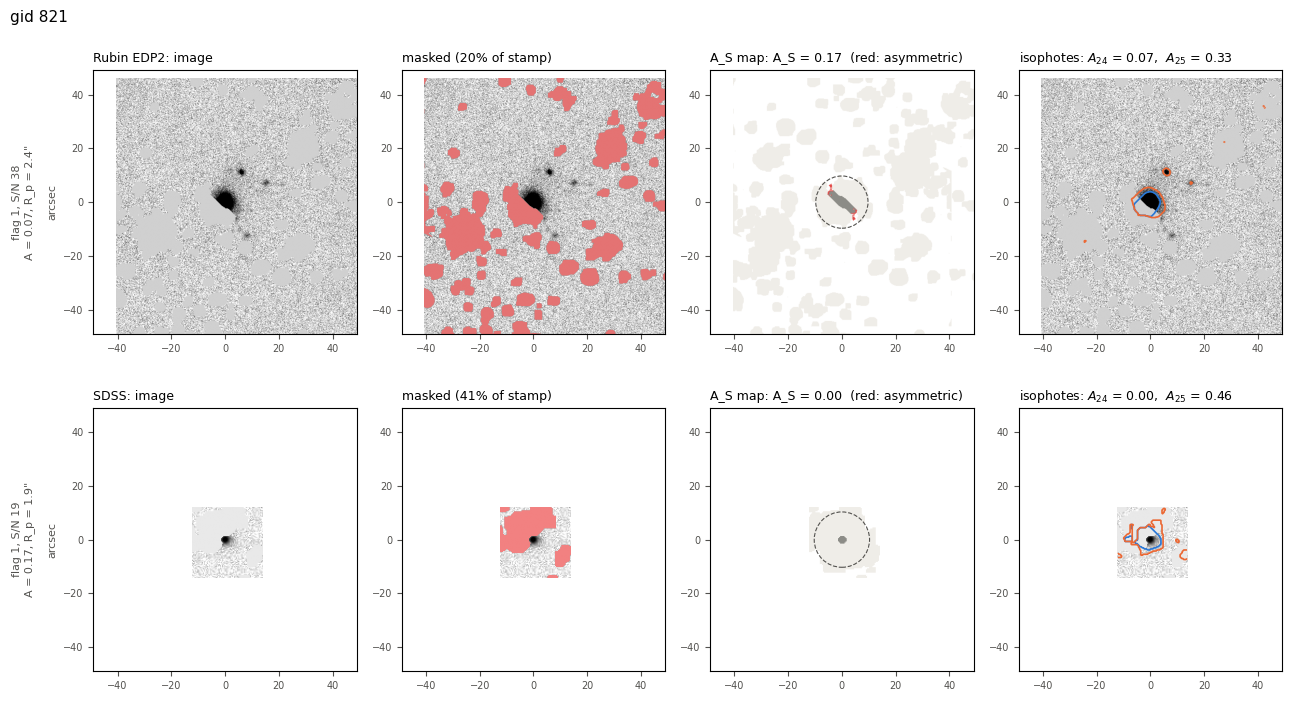

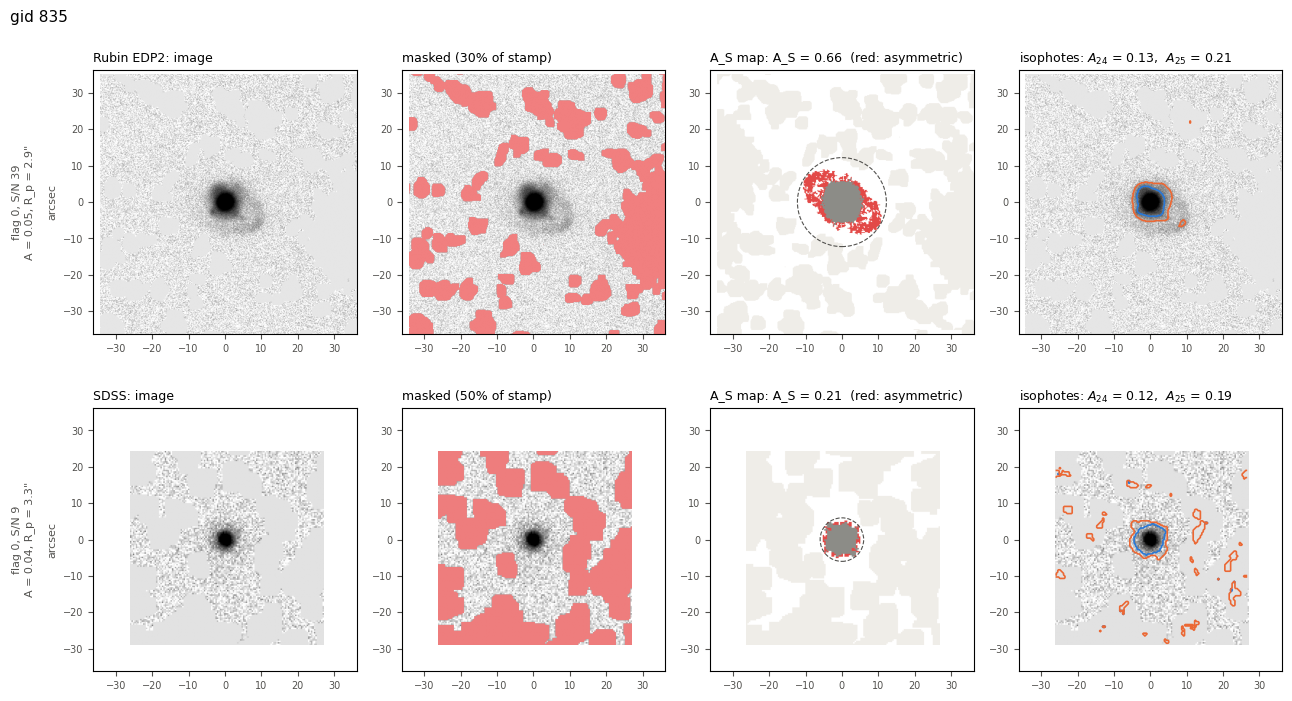

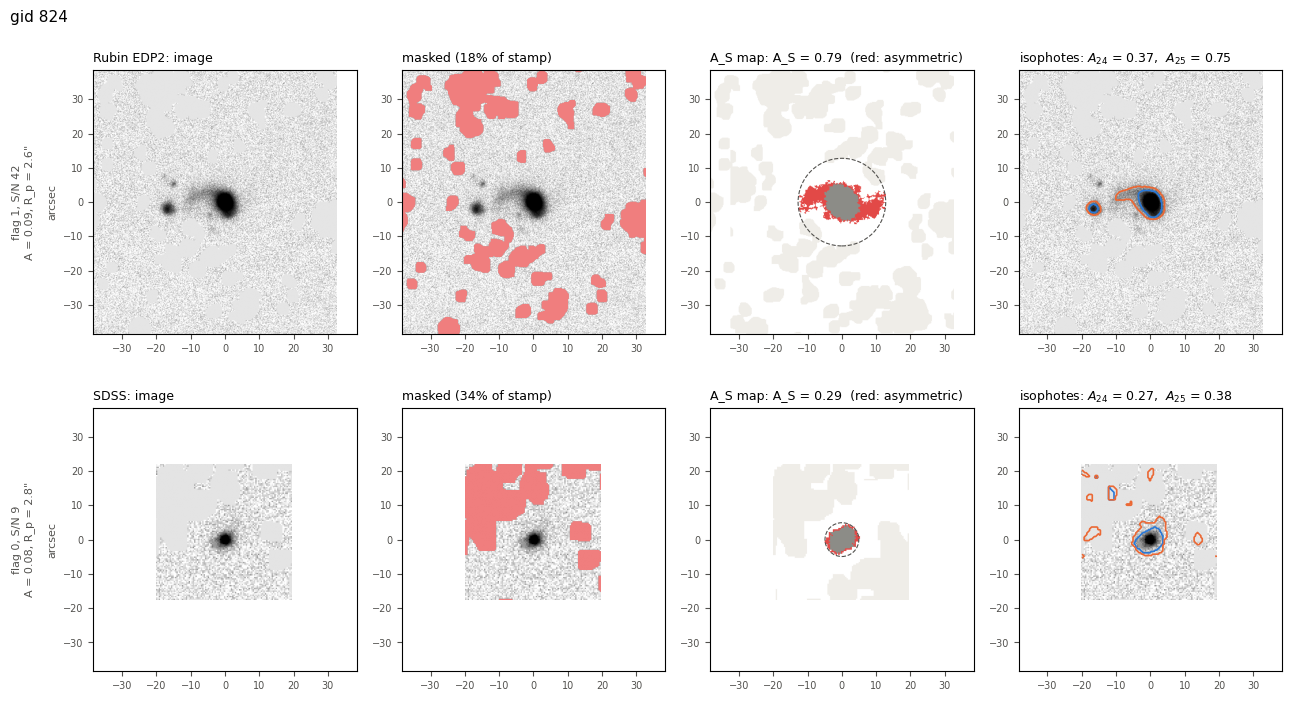

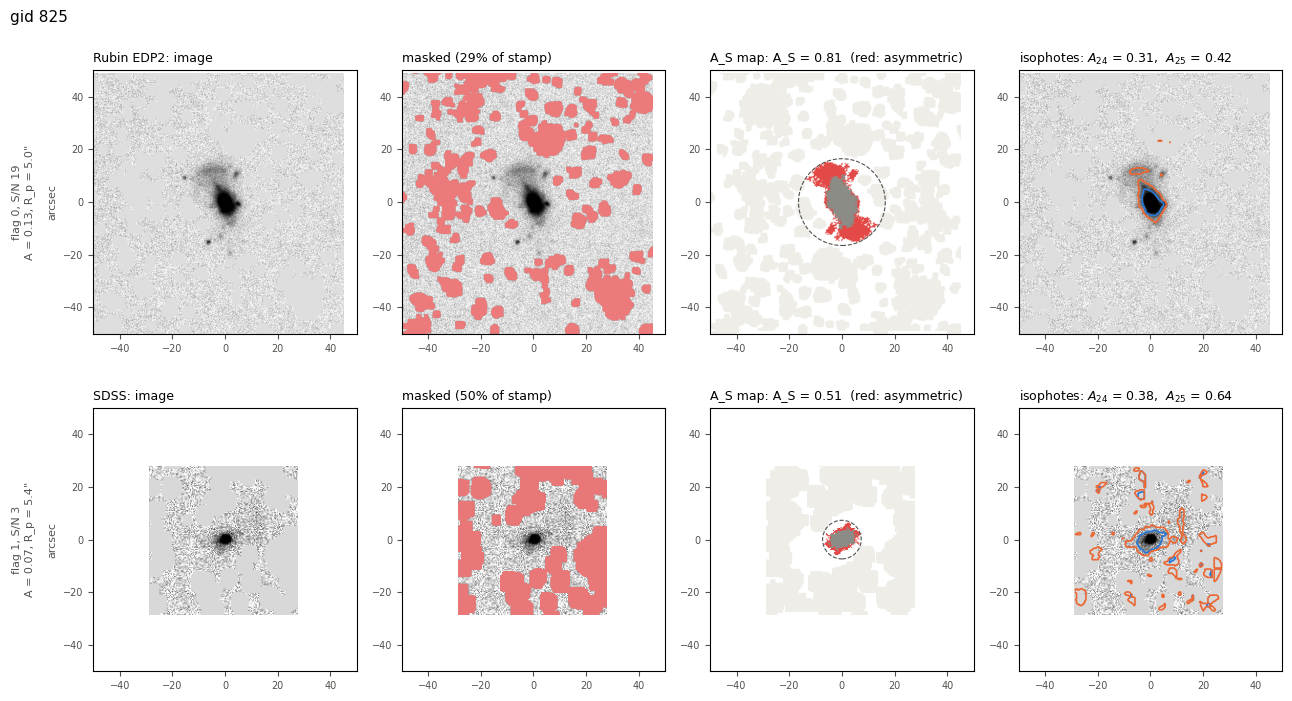

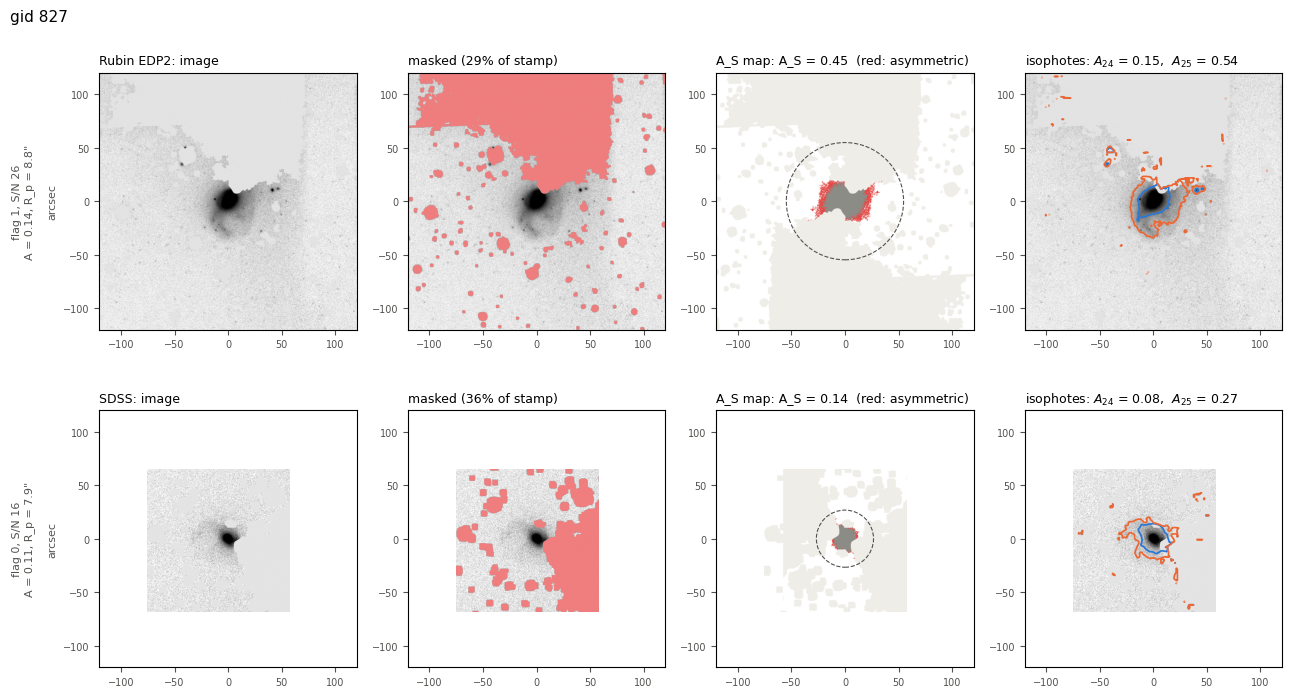

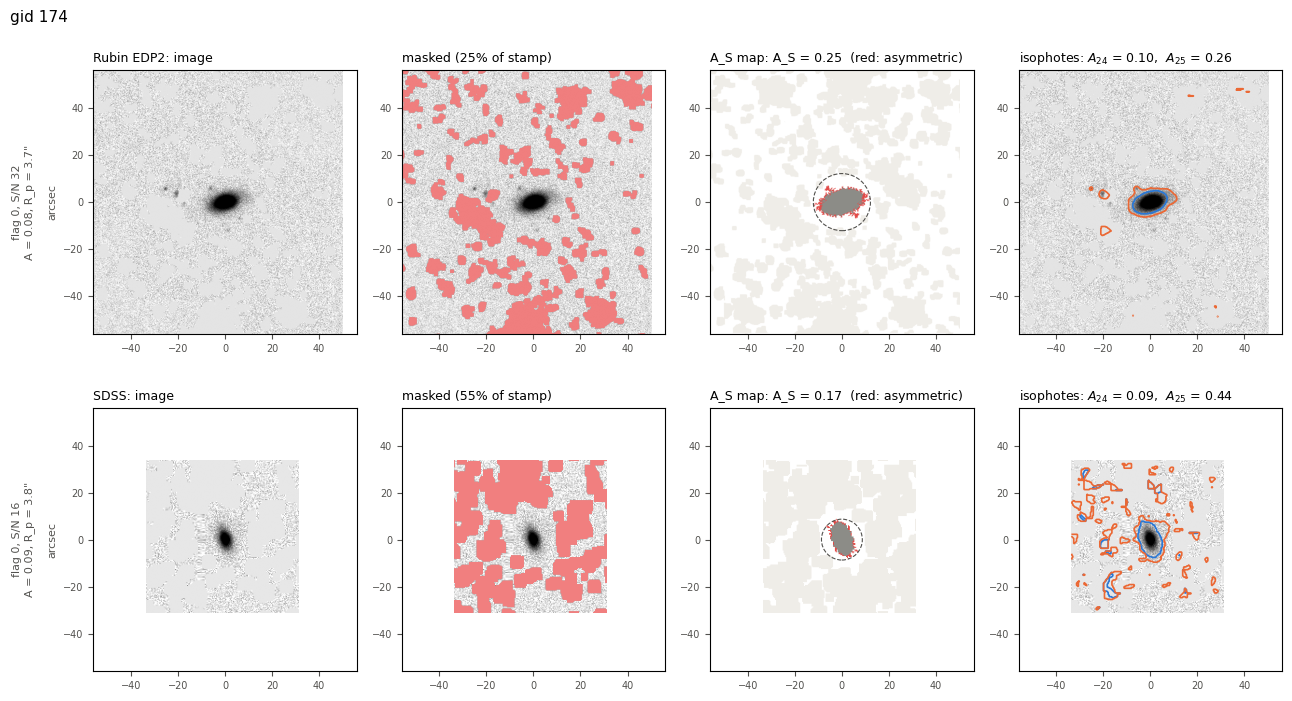

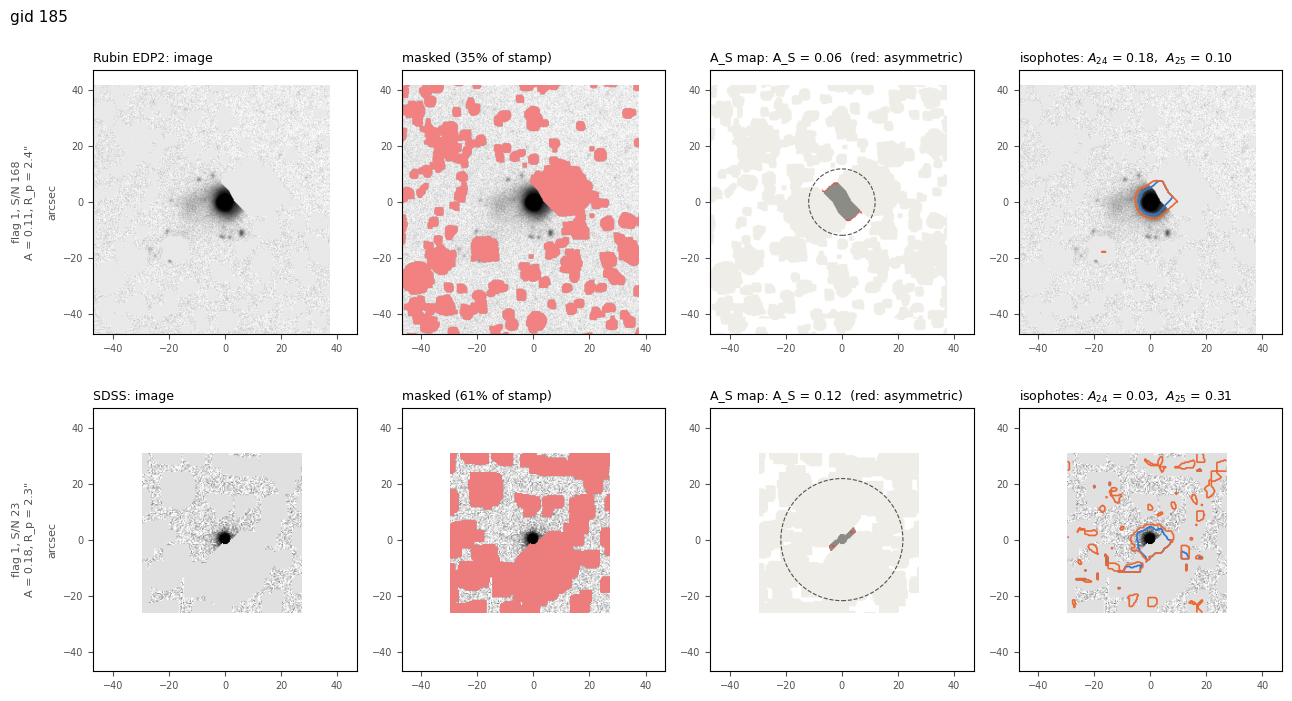

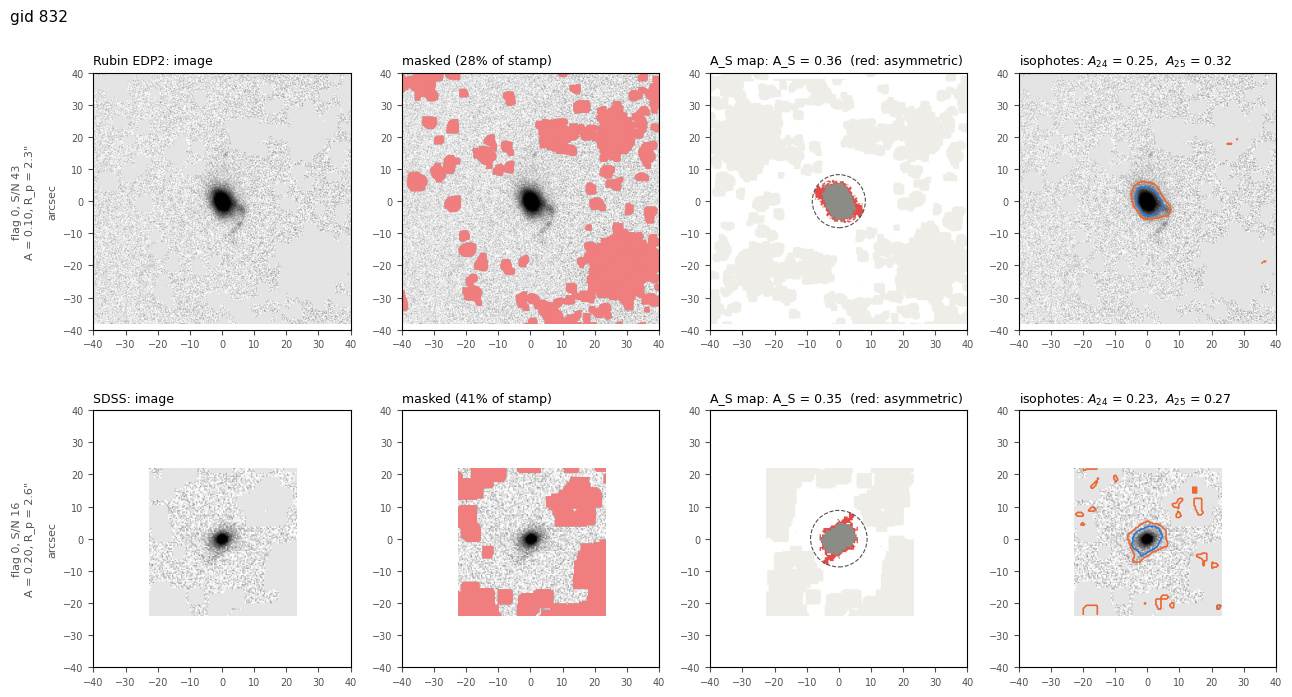

In [14]:
import os, pickle
import numpy as np, matplotlib.pyplot as plt
import skimage.transform

RUBIN_PKL = "goto_dp2_morphology_pkl"      # folder with the Rubin run's {gid}.pkl
SDSS_PKL = "goto_sdss_r_morphology_pkl"      # folder with the SDSS run's {gid}.pkl
PIX = {"Rubin EDP2": 0.2, "SDSS": 0.396}     # arcsec per pixel
ISO_MU = [24, 25]                            # the ISOPHOTES_MU used in the runs (labels only)


def _load(folder, gid):
    path = os.path.join(folder, f"{gid}.pkl")
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def compare(gid, half_arcsec=None, save=None):
    ms = {"Rubin EDP2": _load(RUBIN_PKL, gid), "SDSS": _load(SDSS_PKL, gid)}
    for k, folder in (("Rubin EDP2", RUBIN_PKL), ("SDSS", SDSS_PKL)):
        if ms[k] is None:
            print(f"gid {gid}: no {k} pickle at {os.path.join(folder, f'{gid}.pkl')}")
    ms = {k: v for k, v in ms.items() if v is not None}
    if not ms:
        print(f"gid {gid}: no pickle in either folder"); return
    if half_arcsec is None:                  # same field of view for both: the larger of the two stamps
        half_arcsec = max(max(m._cutout_stamp_maskzeroed.shape) / 2 * PIX[k] for k, m in ms.items())
    fig, axes = plt.subplots(len(ms), 4, figsize=(13, 3.4 * len(ms) + 0.4), squeeze=False)
    for row, (name, m) in enumerate(ms.items()):
        pix, img = PIX[name], m._cutout_stamp_maskzeroed
        ny, nx = img.shape
        xc, yc = m._asymmetry_center         # stamp pixels
        ext = [(-xc - 0.5) * pix, (nx - xc - 0.5) * pix, (-yc - 0.5) * pix, (ny - yc - 0.5) * pix]
        s = m.sky_sigma if m.sky_sigma > 0 else np.nanstd(img)
        stretch = np.arcsinh(img / (3 * s))
        vmax = np.nanpercentile(stretch, 99.7)
        # 1. image
        a = axes[row, 0]
        a.imshow(stretch, origin="lower", cmap="gray_r", extent=ext, vmin=-0.3, vmax=vmax)
        a.set_title(f"{name}: image", fontsize=9, loc="left")
        # 2. masked pixels (neighbours, bad pixels)
        a = axes[row, 1]
        a.imshow(stretch, origin="lower", cmap="gray_r", extent=ext, vmin=-0.3, vmax=vmax)
        a.imshow(np.ma.masked_where(~m._mask_stamp, m._mask_stamp), origin="lower", cmap="autumn", alpha=0.45, extent=ext)
        a.set_title(f"masked ({m._mask_stamp.mean():.0%} of stamp)", fontsize=9, loc="left")
        # 3. shape-asymmetry map: grey = symmetric, red = pixels that don't match their 180-degree rotation
        a = axes[row, 2]
        B = np.asarray(m._segmap_shape_asym, float)
        B180 = skimage.transform.rotate(B, 180.0, center=(xc, yc), order=0)
        msk = m._mask_stamp | (skimage.transform.rotate(m._mask_stamp.astype(float), 180.0, center=(xc, yc), order=0) >= 0.5)
        rgb = np.ones((ny, nx, 3))
        rgb[(B > 0) & (B180 > 0)] = (0.55, 0.55, 0.53)
        rgb[(np.abs(B - B180) > 0) & ~msk] = (0.89, 0.29, 0.28)
        rgb[msk] = (0.94, 0.93, 0.91)
        a.imshow(rgb, origin="lower", extent=ext)
        if m.rmax_circ > 0:
            a.add_patch(plt.Circle((0, 0), m.rmax_circ * pix, fill=False, lw=0.8, ls="--", color="#52514e"))
        a.set_title(f"A_S map: A_S = {m.shape_asymmetry:.2f}  (red: asymmetric)", fontsize=9, loc="left")
        # 4. isophotes used for A_X
        a = axes[row, 3]
        a.imshow(stretch, origin="lower", cmap="gray_r", extent=ext, vmin=-0.3, vmax=vmax)
        iso = getattr(m, "_isophotes", []) or []
        vals = m.isophote_asymmetry if isinstance(m.isophote_asymmetry, (list, tuple, np.ndarray)) else []
        txt = []
        for mk, c, mu, v in zip(iso, ("#2a78d6", "#eb6834"), ISO_MU, vals):
            if np.any(mk):
                a.contour(mk.astype(float), levels=[0.5], colors=[c], linewidths=1.2, extent=ext, origin="lower")
            txt.append(f"$A_{{{mu}}}$ = {v:.2f}" if np.isfinite(v) else f"$A_{{{mu}}}$ = n/a")
        a.set_title("isophotes: " + ",  ".join(txt), fontsize=9, loc="left")
        for a in axes[row]:
            a.set_xlim(-half_arcsec, half_arcsec); a.set_ylim(-half_arcsec, half_arcsec)
            a.tick_params(labelsize=7, colors="#52514e")
        axes[row, 0].set_ylabel(f"flag {m.flag}, S/N {m.sn_per_pixel:.0f}\nA = {m.asymmetry:.2f}, R_p = {m.rpetro_circ * pix:.1f}\"\n\narcsec",
                                fontsize=8, color="#52514e")
    fig.suptitle(f"gid {gid}", x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=130)
    plt.show()


for gid in [821, 835, 824, 825, 827, 174, 185, 832]:
    compare(gid, save=f"compare_figs/gid{gid}.png")

#240 of 240:  control  gid 80906


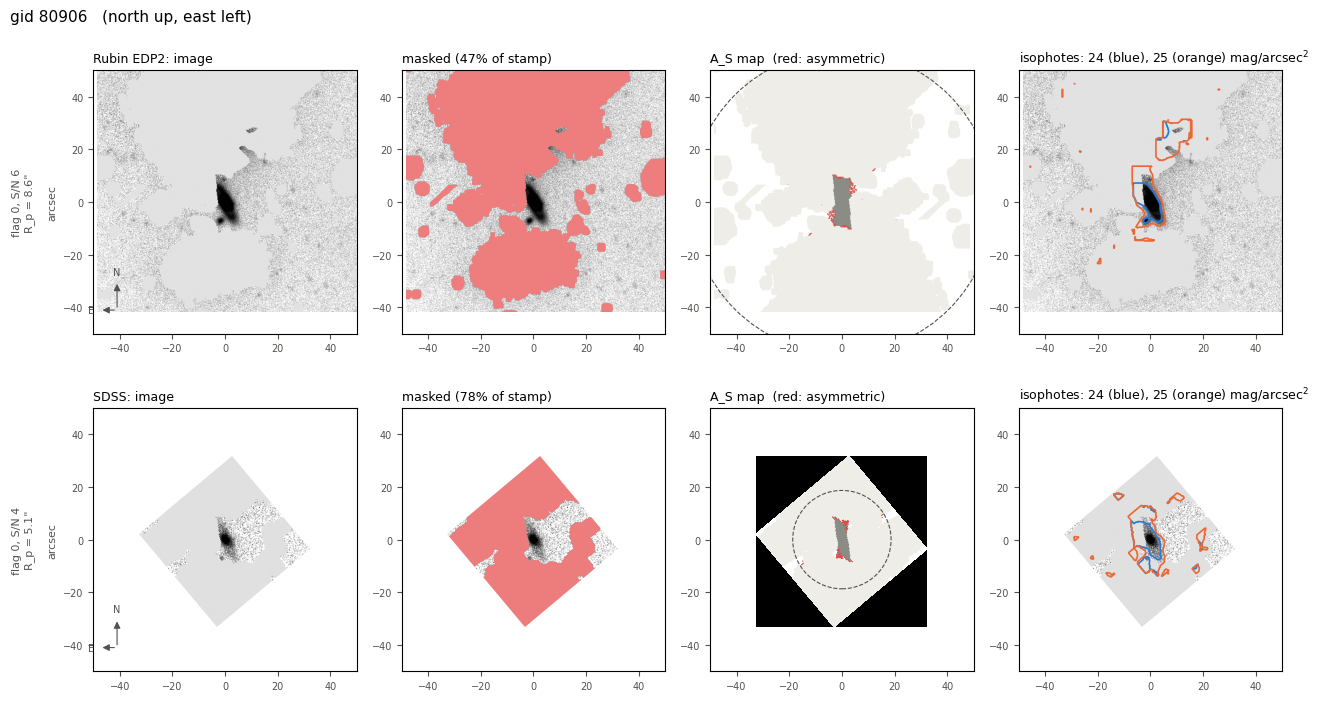

enter = next, q = stop:  


In [12]:
%run inspect_loop.py


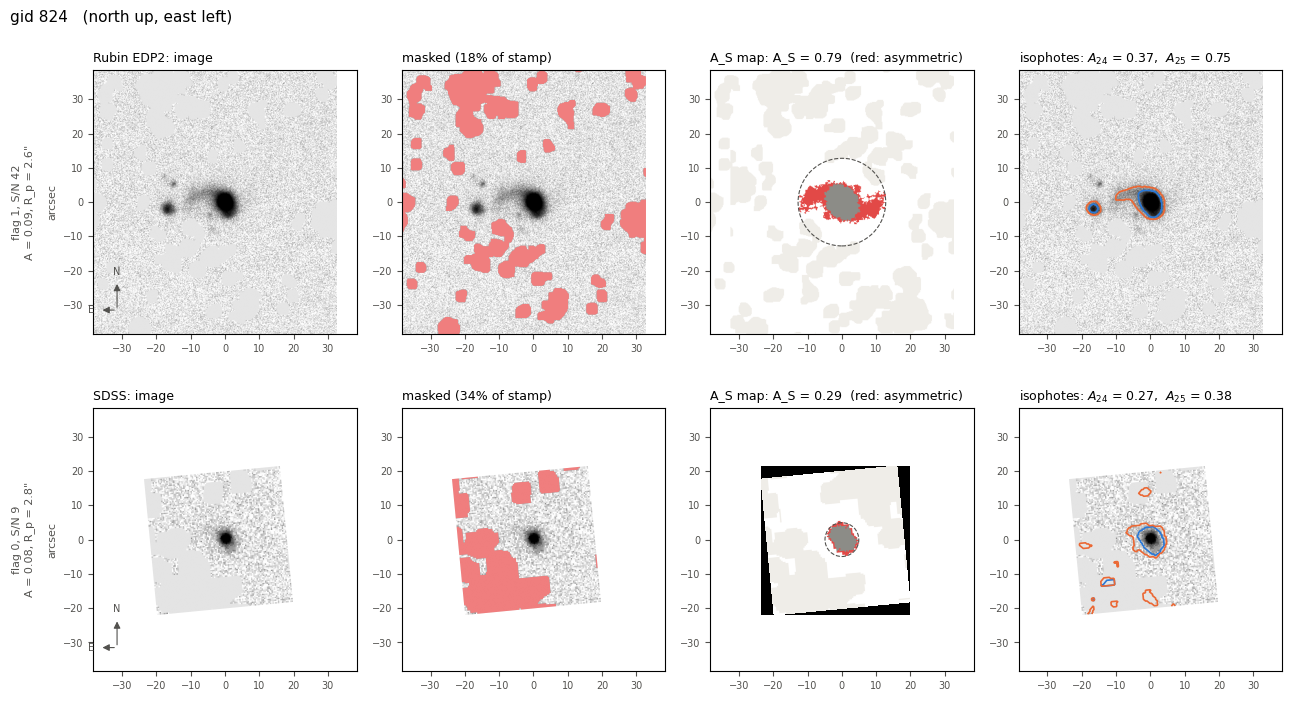

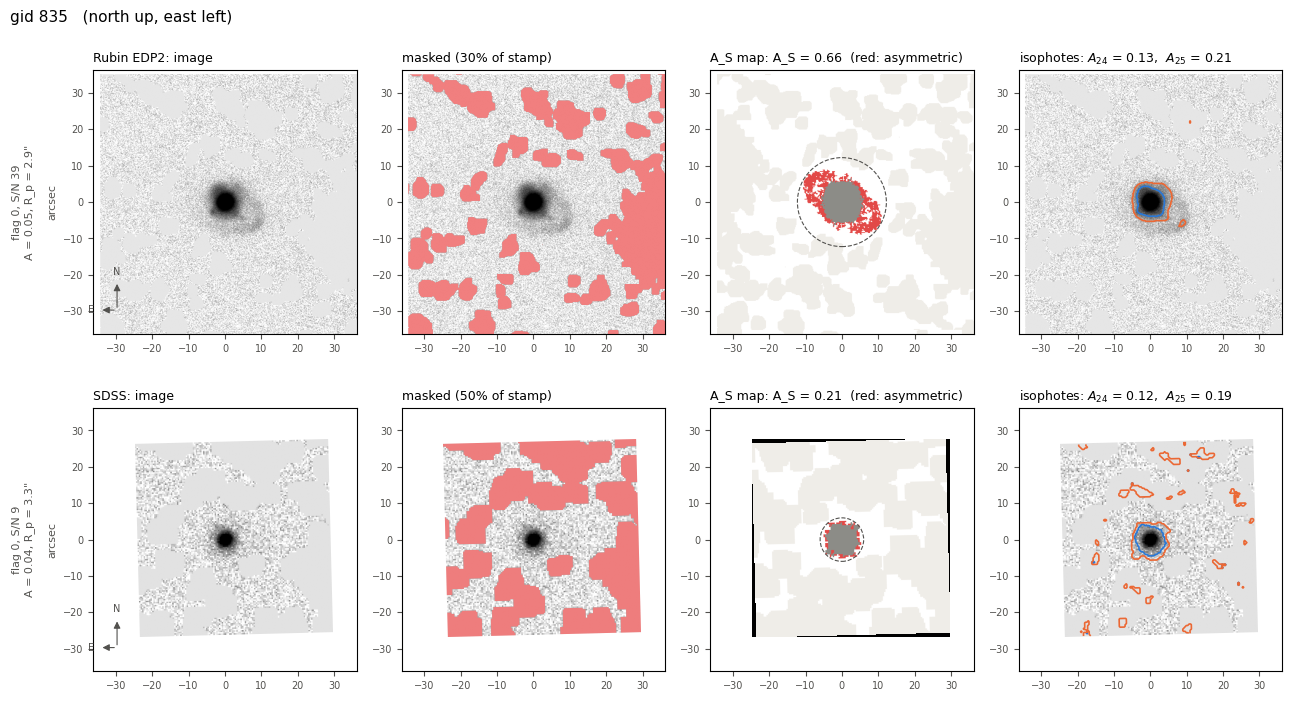

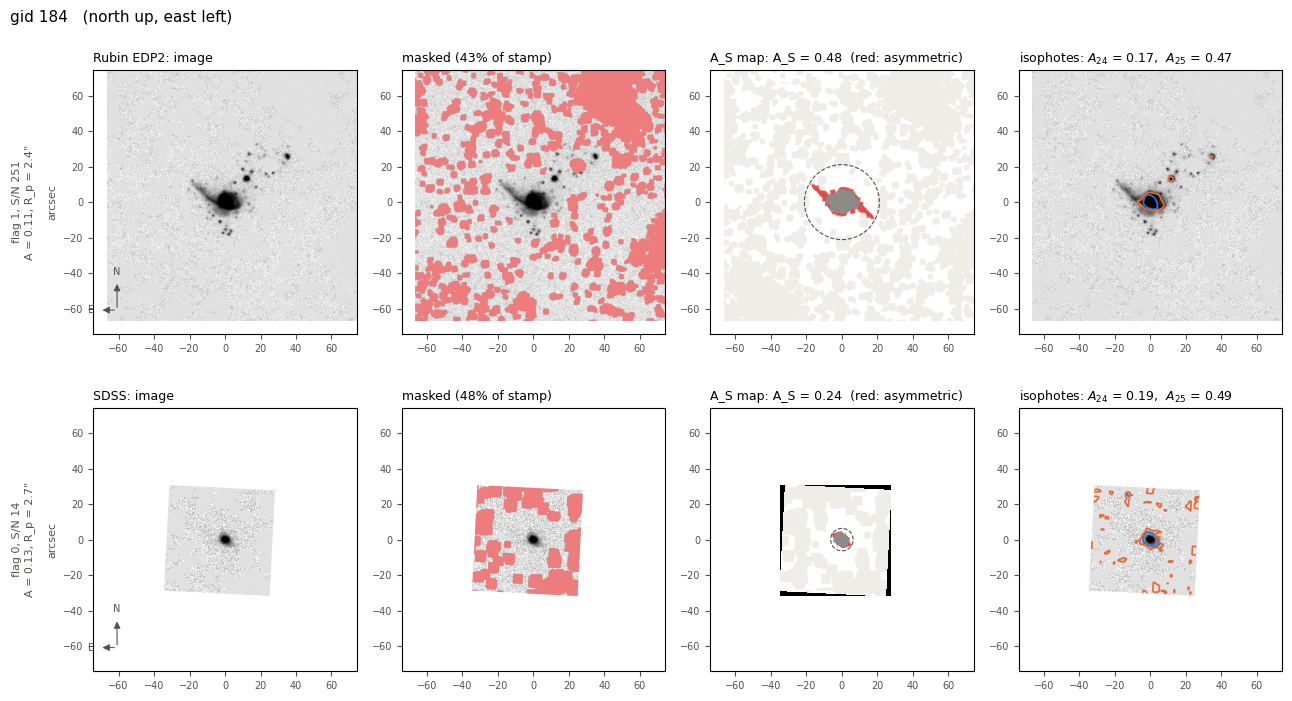

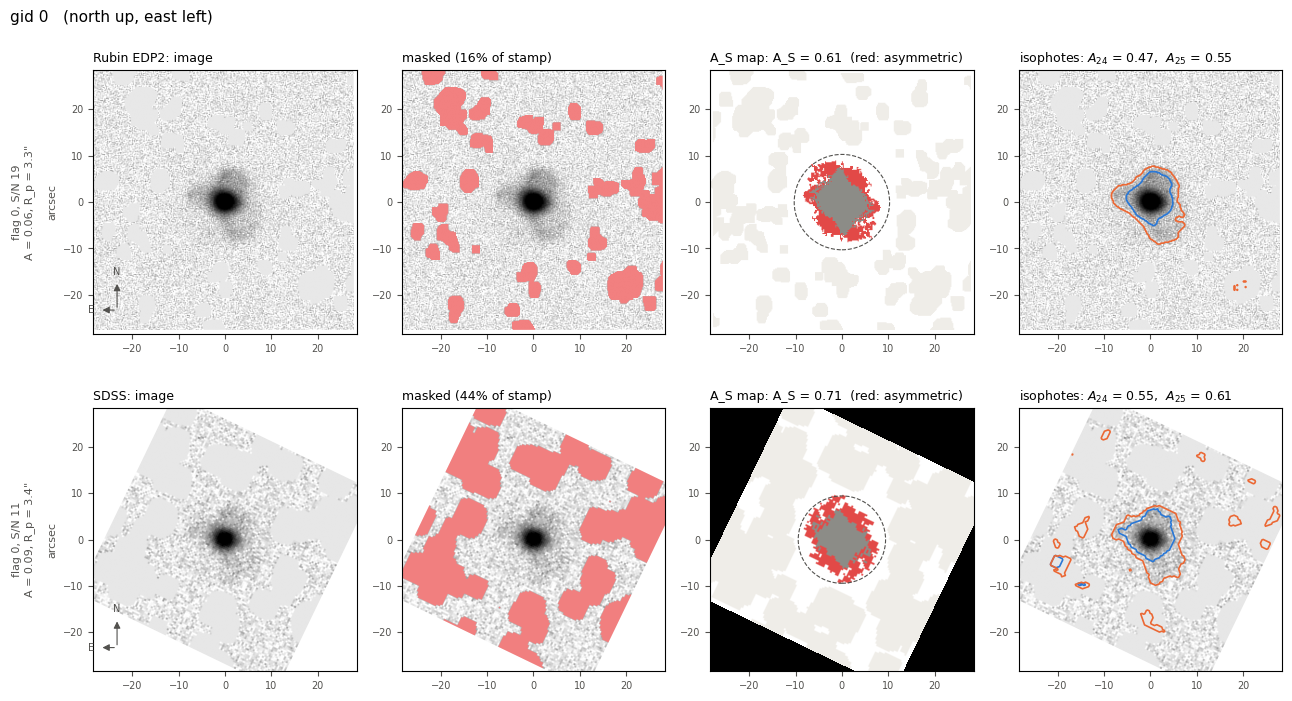

In [26]:
import compare_pkls as cp

cp.RUBIN_PKL, cp.SDSS_PKL = "goto_dp2_morphology_pkl", "goto_sdss_r_morphology_pkl"
cp.RUBIN_CSV, cp.SDSS_CSV = "goto_dp2_morphology.csv", "goto_sdss_r_morphology.csv"

for gid in [824, 835, 184, 0]:
    cp.compare(gid, save=f"compare_figs/talk_gid{gid}.png")